<a href="https://colab.research.google.com/github/u-hihi/IP2026/blob/main/ch06_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
import cv2
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt
drive.mount('/content/gdrive')

Mounted at /content/gdrive


(256, 256)


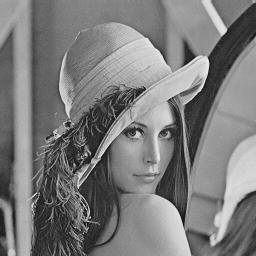

In [2]:
img = cv2.imread('/content/gdrive/My Drive/ColabDIP/images/Images/lena256.jpg')
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gimg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
print(gimg.shape)
cv2_imshow(gimg)

In [3]:
gx = np.array([[-1, 0], [0, 1]], dtype=int)
gy = np.array([[0,-1], [1, 0]], dtype=int)
print(gx)
print(gy)

[[-1  0]
 [ 0  1]]
[[ 0 -1]
 [ 1  0]]


In [4]:
x = cv2.filter2D(gimg, -1, gx)
y = cv2.filter2D(gimg, -1, gy)

In [18]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

In [19]:
#absX = absX * 3
#absY = absY * 3

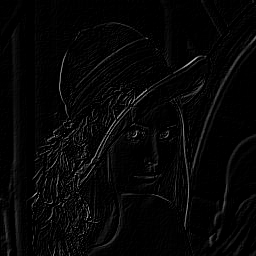

In [20]:
cv2_imshow(absX)
#cv2_imshow(absY)

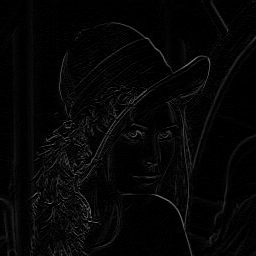

In [21]:
outimg = cv2.addWeighted(absX, 0.5, absY, 0.5, 0)
#outimg = outimg * 3
cv2_imshow(outimg)

In [22]:
gBin = np.zeros(gimg.shape, dtype=np.uint8)

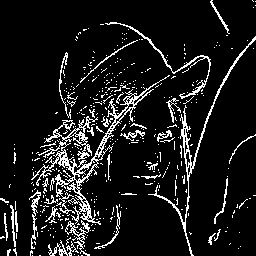

In [23]:
thresold = 15

for h in range(gimg.shape[0]):
  for w in range(gimg.shape[1]):
    if outimg[h, w] > thresold:
      gBin[h, w] = 255

cv2_imshow(gBin)

Sebel

In [46]:
gx = np.array([[1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype= int)
gy = np.array([[1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype= int)
print(gx)
print(gy)

[[ 1  0  1]
 [-2  0  2]
 [-1  0  1]]
[[ 1 -2 -1]
 [ 0  0  0]
 [ 1  2  1]]


In [35]:
x = cv2.filter2D(gimg, -1, gx)
y = cv2.filter2D(gimg, -1, gy)

In [36]:
absX = cv2.convertScaleAbs(x)
absY = cv2.convertScaleAbs(y)

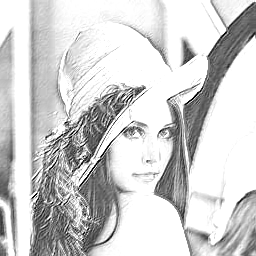

In [37]:
outimg = cv2.addWeighted(absX, 0.5, absY, 0.5, 0)
cv2_imshow(outimg)

In [38]:
gBin = np.zeros(gimg.shape, dtype=np.uint8)

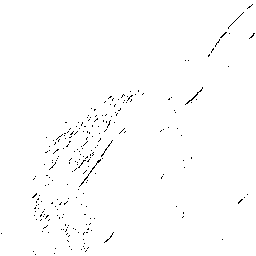

In [39]:
thresold = 50

for h in range(gimg.shape[0]):
  for w in range(gimg.shape[1]):
    if outimg[h, w] > thresold:
      gBin[h, w] = 255

cv2_imshow(gBin)

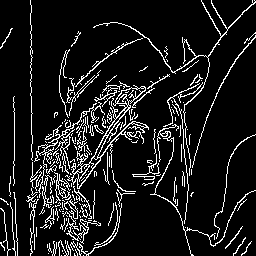

In [40]:
cannyimg = cv2.Canny(gimg, 100, 200)
cv2_imshow(cannyimg)

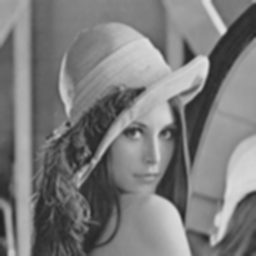

In [41]:
blurimg = cv2.GaussianBlur(gimg, (5, 5), 1.4)
cv2_imshow(blurimg)

In [42]:
x = cv2.filter2D(blurimg, -1, gx)
y = cv2.filter2D(blurimg, -1, gy)

In [44]:
edgeDirection = np.arctan2(y,x)
print(edgeDirection)
print(edgeDirection.shape)

[[0.785  0.785  0.785  ... 0.785  0.785  0.785 ]
 [0.785  0.785  0.785  ... 0.633  0.6094 0.604 ]
 [0.785  0.785  0.785  ... 0.3704 0.2896 0.2532]
 ...
 [0.702  0.676  0.6704 ... 0.817  0.878  0.9746]
 [0.7217 0.6836 0.6587 ... 0.7393 0.8003 0.8926]
 [0.785  0.7456 0.7085 ... 0.627  0.693  0.785 ]]
(256, 256)


In [45]:
angle = np.rad2deg(edgeDirection)
print(angle)

[[45.   45.   45.   ... 45.   45.   45.  ]
 [45.   45.   45.   ... 36.25 34.9  34.6 ]
 [45.   45.   45.   ... 21.22 16.6  14.51]
 ...
 [40.22 38.72 38.4  ... 46.8  50.3  55.84]
 [41.34 39.16 37.75 ... 42.34 45.84 51.16]
 [45.   42.72 40.6  ... 35.9  39.7  45.  ]]
